In [2]:
# 超参数（Hyperparameter）是指在模型训练之前，由人为设定、用于控制模型结构或训练过程的参数。

In [7]:
import torch
import torch.nn.functional as F
import  matplotlib.pyplot as plt
import os
os.environ['KMP_DUPLICATE_LIB_OK']='TRUE'
%matplotlib inline

In [2]:
words = open('names.txt','r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [7]:
### 构建数据集，X表示上下文标签，Y表示期待结果的标签
block_size = 3
X, Y = [], []
for w in words:
    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)#[[0,0,0]]
        Y.append(ix)#[5]
        print(''.join(itos[i] for i in context), '--->', itos[ix])#...--->e
        context = context[1:] + [ix]#[0,0,5]
X = torch.tensor(X)
Y = torch.tensor(Y)

... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
... ---> a
..a ---> v
.av ---> a
ava ---> .
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .
... ---> c
..c ---> h
.ch ---> a
cha ---> r
har ---> l
arl ---> o
rlo ---> t
lot ---> t
ott ---> e
tte ---> .
... ---> m
..m ---> i
.mi ---> a
mia ---> .
... ---> a
..a ---> m
.am ---> e
ame ---> l
mel ---> i
eli ---> a
lia ---> .
... ---> h
..h ---> a
.ha ---> r
har ---> p
arp ---> e
rpe ---> r
per ---> .
... ---> e
..e ---> v
.ev ---> e
eve ---> l
vel ---> y
ely ---> n
lyn ---> .
... ---> a
..a ---> b
.ab ---> i
abi ---> g
big ---> a
iga ---> i
gai ---> l
ail ---> .
... ---> e
..e ---> m
.em ---> i
emi ---> l
mil ---> y
ily ---> .
... ---> e
..e ---> l
.el ---> i
eli ---> z
liz ---> a
iza ---> b
zab ---> e
abe ---> t
bet ---> h
eth ---> .

In [8]:
X.shape, Y.shape,X.dtype,Y.dtype

(torch.Size([228146, 3]), torch.Size([228146]), torch.int64, torch.int64)

In [9]:
### 构造C
C = torch.randn((27,2))
C

tensor([[-4.4874e-01, -2.0335e+00],
        [-5.6420e-01,  6.2419e-01],
        [ 4.9668e-01,  8.2498e-01],
        [-9.6840e-02, -6.0699e-01],
        [-6.8382e-01, -7.9672e-01],
        [-1.4420e+00,  1.4961e+00],
        [ 4.1204e-01,  2.0391e+00],
        [-8.4069e-01,  4.3054e-01],
        [-2.1712e-01,  5.8926e-02],
        [-7.7268e-02,  4.6794e-01],
        [ 7.1375e-01, -1.2353e-03],
        [ 5.3745e-01, -1.0653e+00],
        [ 3.4069e-02,  3.0048e+00],
        [-8.8952e-01,  7.7515e-01],
        [-3.2509e-01, -8.3246e-01],
        [ 1.5303e+00,  2.0224e+00],
        [ 4.9903e-01, -2.0070e+00],
        [ 1.4461e+00,  9.0411e-01],
        [ 1.7097e-01, -9.8362e-01],
        [-9.6633e-03,  1.8424e+00],
        [ 7.2203e-01,  1.0375e+00],
        [-4.2668e-01, -4.2118e-01],
        [ 1.2705e+00,  2.3470e-01],
        [-1.1136e+00, -1.1029e+00],
        [ 5.8536e-01, -3.7602e-02],
        [-1.3205e+00, -1.3585e-01],
        [-1.8265e-01, -4.6516e-01]])

In [10]:
C[5]

tensor([-1.4420,  1.4961])

In [11]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C#1x27 @ 27x2
#可以将这一层看作输入层，输入为每一个字符的独热编码，权重为C，输出为对应的嵌入表示。没有偏置也没有激活函数。

tensor([-1.4420,  1.4961])

In [12]:
C[[5,6,7]]

tensor([[-1.4420,  1.4961],
        [ 0.4120,  2.0391],
        [-0.8407,  0.4305]])

In [13]:
print(X)

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        ...,
        [26, 26, 25],
        [26, 25, 26],
        [25, 26, 24]])


In [14]:
C[X].shape#32*3*2

torch.Size([228146, 3, 2])

In [15]:
C[X]

tensor([[[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-0.4487, -2.0335]],

        [[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-1.4420,  1.4961]],

        [[-0.4487, -2.0335],
         [-1.4420,  1.4961],
         [-0.8895,  0.7752]],

        ...,

        [[-0.1826, -0.4652],
         [-0.1826, -0.4652],
         [-1.3205, -0.1358]],

        [[-0.1826, -0.4652],
         [-1.3205, -0.1358],
         [-0.1826, -0.4652]],

        [[-1.3205, -0.1358],
         [-0.1826, -0.4652],
         [ 0.5854, -0.0376]]])

In [16]:
X[13,2]

tensor(1)

In [17]:
C[X][13,2]

tensor([-0.5642,  0.6242])

In [18]:
C[1]

tensor([-0.5642,  0.6242])

In [19]:
### 构造隐藏层
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [20]:
W1 = torch.randn((6,100))
b1 = torch.randn(100)

In [21]:
# emb @ W1 + b1维度不匹配，需要改变维度。

In [22]:
emb[:, 0, :],emb[:, 1, :],emb[:, 2, :]

(tensor([[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-0.4487, -2.0335],
         ...,
         [-0.1826, -0.4652],
         [-0.1826, -0.4652],
         [-1.3205, -0.1358]]),
 tensor([[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-1.4420,  1.4961],
         ...,
         [-0.1826, -0.4652],
         [-1.3205, -0.1358],
         [-0.1826, -0.4652]]),
 tensor([[-0.4487, -2.0335],
         [-1.4420,  1.4961],
         [-0.8895,  0.7752],
         ...,
         [-1.3205, -0.1358],
         [-0.1826, -0.4652],
         [ 0.5854, -0.0376]]))

In [23]:
torch.cat([emb[:, 0, :],emb[:, 1, :],emb[:, 2, :]],1)#emb[:, 0, :]-->32*2,沿着emb[:, 0, :]的维度1进行拼接，
#也就是横向拼接

tensor([[-0.4487, -2.0335, -0.4487, -2.0335, -0.4487, -2.0335],
        [-0.4487, -2.0335, -0.4487, -2.0335, -1.4420,  1.4961],
        [-0.4487, -2.0335, -1.4420,  1.4961, -0.8895,  0.7752],
        ...,
        [-0.1826, -0.4652, -0.1826, -0.4652, -1.3205, -0.1358],
        [-0.1826, -0.4652, -1.3205, -0.1358, -0.1826, -0.4652],
        [-1.3205, -0.1358, -0.1826, -0.4652,  0.5854, -0.0376]])

In [24]:
torch.unbind(emb, dim=1)

(tensor([[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-0.4487, -2.0335],
         ...,
         [-0.1826, -0.4652],
         [-0.1826, -0.4652],
         [-1.3205, -0.1358]]),
 tensor([[-0.4487, -2.0335],
         [-0.4487, -2.0335],
         [-1.4420,  1.4961],
         ...,
         [-0.1826, -0.4652],
         [-1.3205, -0.1358],
         [-0.1826, -0.4652]]),
 tensor([[-0.4487, -2.0335],
         [-1.4420,  1.4961],
         [-0.8895,  0.7752],
         ...,
         [-1.3205, -0.1358],
         [-0.1826, -0.4652],
         [ 0.5854, -0.0376]]))

In [25]:
torch.cat(torch.unbind(emb, dim=1),1)#方便复用，这样就算block_size()发生改变，也不需要重写

tensor([[-0.4487, -2.0335, -0.4487, -2.0335, -0.4487, -2.0335],
        [-0.4487, -2.0335, -0.4487, -2.0335, -1.4420,  1.4961],
        [-0.4487, -2.0335, -1.4420,  1.4961, -0.8895,  0.7752],
        ...,
        [-0.1826, -0.4652, -0.1826, -0.4652, -1.3205, -0.1358],
        [-0.1826, -0.4652, -1.3205, -0.1358, -0.1826, -0.4652],
        [-1.3205, -0.1358, -0.1826, -0.4652,  0.5854, -0.0376]])

In [26]:
#下面介绍另一种方法，更方便
a = torch.arange(18)
a.view(3,3,2)

tensor([[[ 0,  1],
         [ 2,  3],
         [ 4,  5]],

        [[ 6,  7],
         [ 8,  9],
         [10, 11]],

        [[12, 13],
         [14, 15],
         [16, 17]]])

In [27]:
a.storage()

C:\Users\lirui\AppData\Local\Temp\ipykernel_15812\214256462.py:1: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  a.storage()


 0
 1
 2
 3
 4
 5
 6
 7
 8
 9
 10
 11
 12
 13
 14
 15
 16
 17
[torch.storage.TypedStorage(dtype=torch.int64, device=cpu) of size 18]

In [28]:
#back mlp
emb.view(32, 6)

RuntimeError: shape '[32, 6]' is invalid for input of size 1368876

In [29]:
# h = emb.view(32, 6) @ W1 + b1
# h = emb.view(emb.shape[0], 6) @ W1 + b1
h = emb.view(-1, 6) @ W1 + b1

In [30]:
h = torch.tanh(h)
h

tensor([[ 0.8134, -0.7216, -1.0000,  ..., -1.0000,  0.5802, -0.9861],
        [ 0.9995,  0.9938,  0.0071,  ..., -0.9942,  0.8363, -1.0000],
        [ 0.8529, -0.4046,  0.9925,  ...,  0.7578,  0.9969, -0.9922],
        ...,
        [ 0.9748, -0.7623,  0.5831,  ..., -0.9715,  0.2115, -0.9892],
        [ 0.9267, -0.9404, -0.9130,  ..., -0.8731,  0.7644,  0.9778],
        [-0.9920, -0.9957, -0.9759,  ..., -0.9162, -0.0410,  0.2847]])

In [31]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [32]:
logits = h @ W2 +b2
logits

tensor([[-3.4758, -5.2664, -1.1926,  ..., 17.2465,  0.3861,  1.2951],
        [ 8.3419, -7.1301, -4.8344,  ..., 19.7341, -5.3423, -5.9871],
        [-0.1903,  1.6961, -4.9781,  ...,  0.1789,  9.3905,  0.1347],
        ...,
        [-3.9404, -3.7260, -8.0594,  ..., 19.4778,  9.3094, -7.3377],
        [-6.3454,  1.3176, -2.3344,  ...,  1.2446,  3.9787,  2.1551],
        [-5.9627,  6.8814,  1.3390,  ..., 13.1999, -8.4320, -5.6273]])

In [33]:
counts = logits.exp()
prob = counts/ counts.sum(1,keepdim=True)
prob

tensor([[5.7591e-11, 9.6098e-12, 5.6484e-10,  ..., 5.7536e-02, 2.7386e-09,
         6.7971e-09],
        [1.1266e-05, 2.1496e-12, 2.1349e-11,  ..., 9.9852e-01, 1.2847e-11,
         6.7413e-12],
        [1.5284e-07, 1.0081e-06, 1.2732e-09,  ..., 2.2108e-07, 2.2137e-03,
         2.1154e-07],
        ...,
        [6.7391e-11, 8.3504e-11, 1.0958e-12,  ..., 9.9775e-01, 3.8277e-05,
         2.2553e-12],
        [1.9310e-14, 4.1096e-11, 1.0659e-12,  ..., 3.8201e-11, 5.8813e-10,
         9.4955e-11],
        [1.3348e-09, 5.0527e-04, 1.9792e-06,  ..., 2.8031e-01, 1.1299e-10,
         1.8668e-09]])

In [34]:
Y

tensor([ 5, 13, 13,  ..., 26, 24,  0])

In [35]:
prob[torch.arange(32), Y]#[0,1,……,31],Y也是32,可以逐个匹配。

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [36]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [37]:
### ------------------

In [38]:
X.shape, Y.shape, C.shape

(torch.Size([228146, 3]), torch.Size([228146]), torch.Size([27, 2]))

In [39]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [40]:
sum(p.nelement() for p in parameters)

3481

In [41]:
emb = C[X]  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
# counts = logits.exp()
# prob = counts / counts.sum(1, keepdims=True)
# loss = -prob[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Y)
loss

tensor(19.5052)

In [42]:
###之前方法的缺陷
logits = torch.tensor([-100,-3,0,100])
counts = logits.exp()
print("counts:",counts)
prob = counts/ counts.sum()
print("prob:  ",prob)

counts: tensor([3.7835e-44, 4.9787e-02, 1.0000e+00,        inf])
prob:   tensor([0., 0., 0., nan])


In [43]:
###pytorch内部会加上最大值的负数，来维持数据的稳定性，确保数据能够正常运算
logits = torch.tensor([-5,-3,0,100])-100
#根据数学公式，其实这里可以加上任意常数，不改变最后的结果
counts = logits.exp()
print("counts:",counts)
prob = counts/ counts.sum()
print("prob:  ",prob)

counts: tensor([0.0000e+00, 1.4013e-45, 3.7835e-44, 1.0000e+00])
prob:   tensor([0.0000e+00, 1.4013e-45, 3.7835e-44, 1.0000e+00])


In [44]:
for p in parameters:
    p.requires_grad = True


In [45]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
#为什么不能设置为线性的？例如，lrs = torch.linspace(0, 1, 1000)，反而要套一层指数？
#假设

In [48]:
lri = []
lossi = []
for i in range(1000):
    ### minibatch construct.与其计算精确梯度而减少更新步数。不如采用近似梯度并增加更新步数。
    ix = torch.randint(0, X.shape[0], (32,))
    ### forward pass
    emb = C[X[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])
    print(loss.item())
    ### backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    ### update
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad
    ### track stats
    lri.append(lre[i])
    lossi.append(loss.item())

7.71885347366333
9.268196105957031
6.793742656707764
8.721961975097656
6.899327754974365
6.740645408630371
7.178979396820068
6.3279032707214355
6.843739032745361
7.056708335876465
6.780993461608887
7.0435099601745605
7.0635809898376465
7.093352794647217
7.147741794586182
8.642810821533203
7.934639930725098
7.8798933029174805
7.539067268371582
8.229724884033203
6.083930015563965
6.94766902923584
7.213390350341797
7.203926086425781
6.656178951263428
7.233616828918457
7.128478527069092
7.430699825286865
7.00286340713501
7.962628364562988
8.054338455200195
9.274826049804688
6.98847770690918
8.185894966125488
8.427437782287598
6.937149524688721
8.397228240966797
8.172972679138184
8.755879402160645
7.169933319091797
9.140379905700684
7.12061071395874
5.93268346786499
6.370368003845215
7.815863609313965
6.796300888061523
6.745165824890137
6.743760108947754
6.82503604888916
6.061047077178955
6.805416584014893
7.3695173263549805
8.118990898132324
5.868180751800537
6.359358787536621
7.1720089912

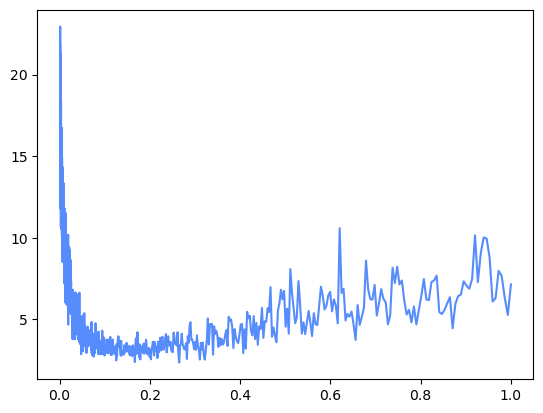

In [47]:
plt.plot(lri, lossi)#横坐标

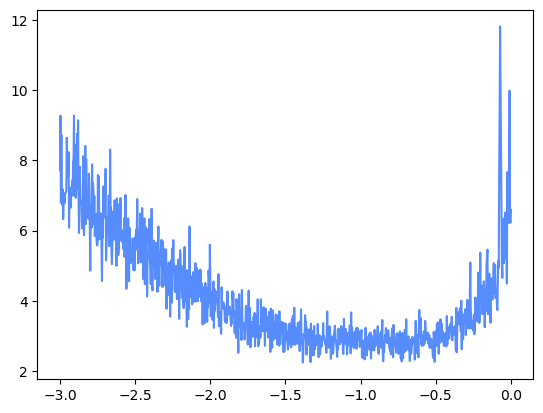

In [49]:
plt.plot(lri, lossi)#横坐标

In [135]:
emb = C[X]  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(logits, Y)
loss

tensor(2.4730, grad_fn=<NllLossBackward0>)

In [130]:
###会发现每次只需要循环十次，但运行速度仍然很慢，因为每次都要处理两万多个样本。
###我们可以将原本的数据集分为多个批次，每次只对其中的一个小批次进行处理。
###这样可以加快训练速度，但又带来另一个问题，怎么确定步长？每次都是随机的一批样本，根本无法确定步长。
###GPT：我们不追求每一步都精确调整步长，而是使用一个整体合适的学习率（learning rate），并通过学习率策略动态调整。

In [117]:
# torch.randint(0,5,(32,))
torch.randint(0, X.shape[0], (32,))

tensor([ 51395, 131664, 180684, 202769,  56155, 224428,  75820,   6575, 127983,
         47050, 116417,   1201, 105989, 129784, 139189,  92465, 207528, 190324,
        161761, 103166,  80350,   3038, 219529,  64097,  62800, 191867, 145050,
        144705, 132103, 177051, 186797,  56771])

In [138]:
# 线性搜索学习率是在数轴上均匀分布，但学习率本质上是指数尺度的问题；
# log 搜索是在倍率上均匀分布，更适合寻找合适的学习率。
lre = torch.linspace(-3, 0, 1000)#
lrs = 10**lre#变化越来越快的学习率
lrs

tensor([0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0010, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011, 0.0011,
        0.0011, 0.0011, 0.0011, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012,
        0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0012, 0.0013, 0.0013, 0.0013,
        0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0013, 0.0014,
        0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014, 0.0014,
        0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015, 0.0015,
        0.0015, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016, 0.0016,
        0.0016, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017, 0.0017,
        0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0018, 0.0019,
        0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0019, 0.0020, 0.0020,
        0.0020, 0.0020, 0.0020, 0.0020, 0.0020, 0.0021, 0.0021, 0.0021, 0.0021,
        0.0021, 0.0021, 0.0021, 0.0022, 

In [ ]:
# lri = []
# lossi = []
for i in range(1000):
    ### minibatch construct.与其计算精确梯度而减少更新步数。不如采用近似梯度并增加更新步数。
    ix = torch.randint(0, X.shape[0], (32,))
    ### forward pass
    emb = C[X[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])
    # print(loss.item())
    ### backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    ### update
    lr = 0.001#之后进行衰减学习率
    for p in parameters:
        p.data += -lr * p.grad
    ### track stats
    # lri.append(lre[i])
    # lossi.append(loss.item())

| 数据集 | 作用 | 回答的问题 |
|-|-|-|
| 训练集 | 学习参数 | **模型怎么学？** |
| 验证集 | 调整模型和超参数 | **哪个模型更好？** |
| 测试集 | 最终评价 | **模型真正泛化能力怎么样？** |

In [1]:
import torch
import torch.nn.functional as F
import  matplotlib.pyplot as plt
import os
os.environ['KMP_DUPLICATE_LIB_OK']='TRUE'
%matplotlib inline

In [2]:
words = open('names.txt','r').read().splitlines()
len(words)

32033

In [3]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [4]:
# build the dataset

def build_dataset(words):
    block_size = 3  # context length: how many characters do we take to predict the next one?
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '-->', itos[ix])
            context = context[1:] + [ix]  # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)

    return X, Y


import random

random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [5]:
Xtr.shape,Ytr.shape

(torch.Size([182625, 3]), torch.Size([182625]))

In [6]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [7]:
sum(p.nelement() for p in parameters)

11897

In [8]:
for p in parameters:
    p.requires_grad = True

In [9]:
lri = []
lossi = []
stepi = []

In [19]:
for i in range(200000):
    ### minibatch construct.与其计算精确梯度而减少更新步数。不如采用近似梯度并增加更新步数。
    ix = torch.randint(0, Xtr.shape[0], (32,))
    ### forward pass
    emb = C[Xtr[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])
    # print(loss.item())
    ### backward pass
    for p in parameters:
        p.grad = None
    loss.backward()
    ### update
    # lr = 0.01#之后进行衰减学习率
    lr = 0.1 if i<10000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad
    ### track stats
    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

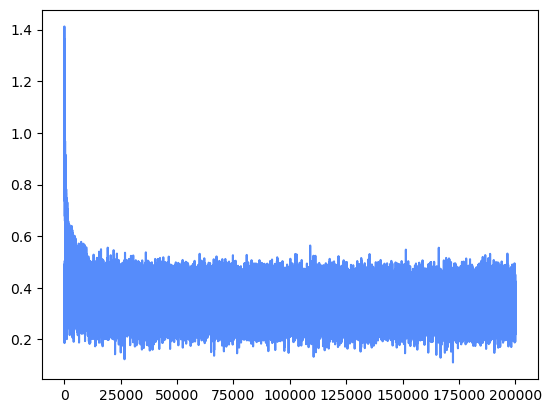

In [20]:
plt.plot(stepi, lossi)

In [21]:
print(loss.item())

2.5042638778686523


In [22]:
emb = C[Xtr]  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1806, grad_fn=<NllLossBackward0>)

In [23]:
emb = C[Xdev]  # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)  # (32, 100)
logits = h @ W2 + b2  # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2061, grad_fn=<NllLossBackward0>)

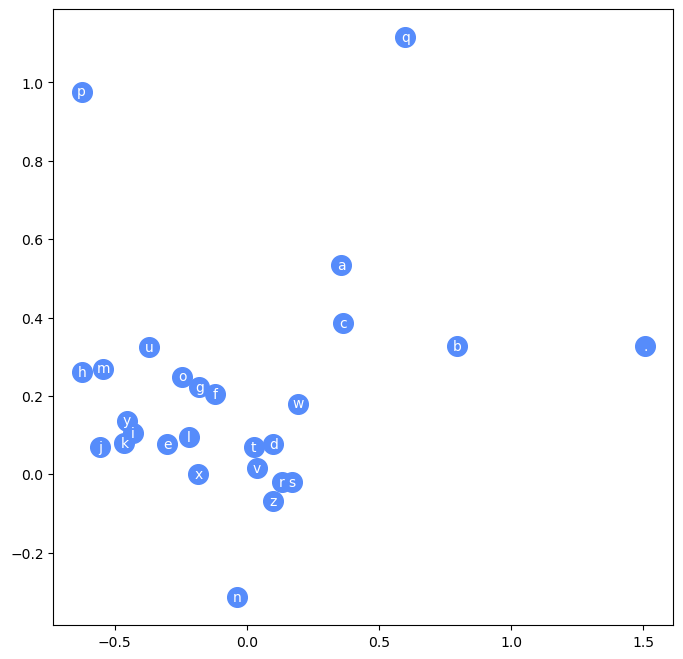

In [24]:
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color="white")

In [27]:
# sample from the model
block_size =3
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size  # initialize with all ...

    while True:
        emb = C[torch.tensor([context])]  # (1,block_size,d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:
            break

    print(''.join(itos[i] for i in out))
print(loss)

mora.
kayanniee.
mad.
ryla.
revyr.
jendraeg.
aderydielin.
shy.
jenre.
elieananaraylynn.
hotalin.
shubergiaganel.
kin.
renlynn.
nophirous.
kynd.
ryyah.
fiel.
yula.
mystonah.
tensor(2.2061, grad_fn=<NllLossBackward0>)
